In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage.metrics import peak_signal_noise_ratio as psnr

# Load original document
original = cv2.imread("Test.jpeg", cv2.IMREAD_GRAYSCALE)

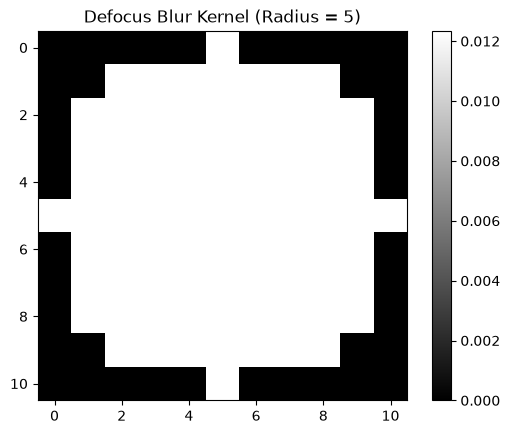

In [3]:
def create_defocus_kernel(radius=5):

    # Calculate the diameter of the circular kernel.
    # A radius of 5 produces an 11x11 matrix.
    size = 2 * radius + 1

    # Create a square matrix filled with zeros.
    kernel = np.zeros((size, size), dtype=np.float32)

    # Find the centre of the matrix.
    centre = (radius, radius)

    # Draw a filled white circle inside the matrix.
    # -1 means fill the entire circle.
    cv2.circle(
        kernel,
        centre,
        radius,
        1,
        -1
    )

    # Normalise the kernel so its values sum to 1.
    # This preserves overall image brightness.
    kernel /= kernel.sum()

    # Return the completed disk-shaped kernel.
    return kernel


# Generate a defocus kernel with radius 5
defocus_kernel = create_defocus_kernel(radius=5)

# Display the kernel
plt.imshow(defocus_kernel, cmap="gray")
plt.title("Defocus Blur Kernel (Radius = 5)")
plt.colorbar()
plt.show()

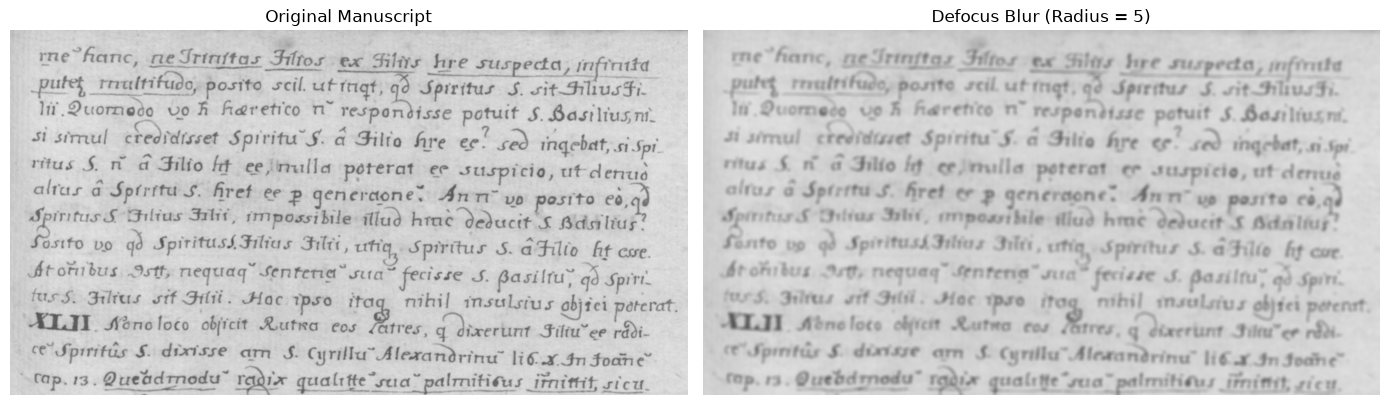

In [4]:
# Apply the circular kernel to our original manuscript
defocus_blurred = cv2.filter2D(
    original,
    -1,
    defocus_kernel
)

# Display the original and blurred manuscript
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(original, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Manuscript")
axes[0].axis("off")

axes[1].imshow(defocus_blurred, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Defocus Blur (Radius = 5)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [5]:
# Wiener deconvolution
def wiener_deblur(image, kernel, K=0.001):
    image = image.astype(np.float32) / 255.0

    # Pad and align kernel with the image
    h, w = image.shape
    kh, kw = kernel.shape

    psf = np.zeros((h, w), dtype=np.float32)
    psf[:kh, :kw] = kernel
    psf = np.roll(psf, (-kh // 2 + 1, -kw // 2 + 1), axis=(0, 1))

    # Fourier transforms
    G = np.fft.fft2(image)
    H = np.fft.fft2(psf)

    # Wiener filter
    F = (np.conj(H) / (np.abs(H)**2 + K)) * G

    # Convert back to spatial domain
    restored = np.real(np.fft.ifft2(F))

    return np.clip(restored * 255, 0, 255).astype(np.uint8)


In [6]:
# Attempt to reverse the defocus blur
defocus_restored = wiener_deblur(
    defocus_blurred,
    defocus_kernel,
    K=0.001887
)

# Calculate PSNR
blurred_score = psnr(
    original,
    defocus_blurred,
    data_range=255
)

restored_score = psnr(
    original,
    defocus_restored,
    data_range=255
)

# Display results
print(f"Defocus Blurred PSNR: {blurred_score:.2f} dB")
print(f"Wiener Restored PSNR: {restored_score:.2f} dB")
print(f"Improvement: {restored_score - blurred_score:.2f} dB")

Defocus Blurred PSNR: 25.95 dB
Wiener Restored PSNR: 31.70 dB
Improvement: 5.74 dB


Defocus Blurred PSNR: 25.95 dB
Wiener Restored PSNR: 31.70 dB
Improvement: 5.74 dB


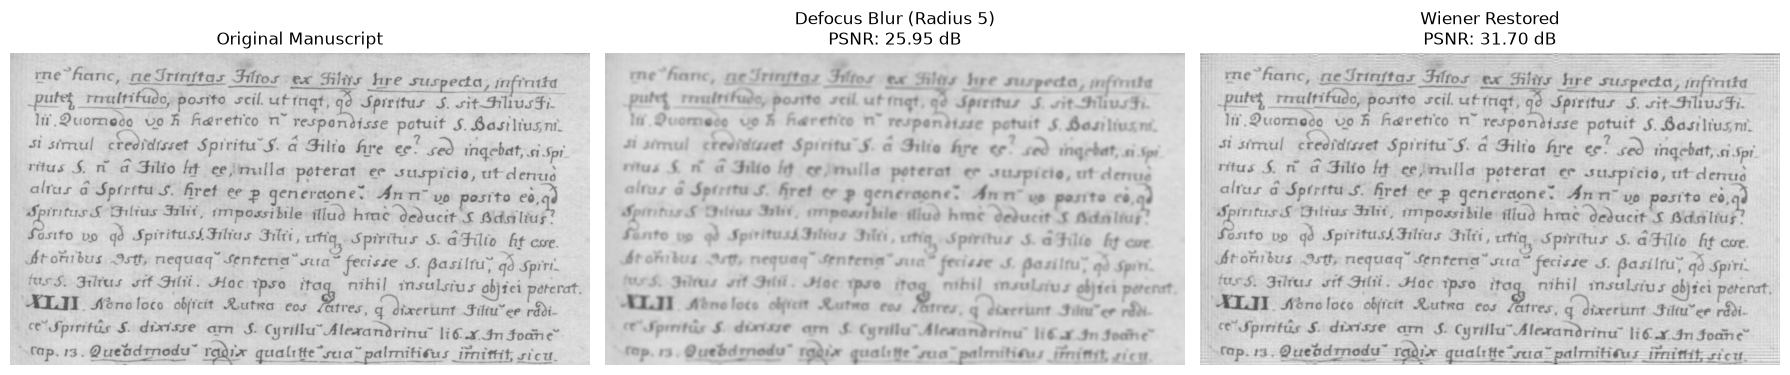

In [7]:
# Restore the defocused manuscript using Wiener deconvolution
# K controls regularisation to prevent excessive noise amplification
defocus_restored = wiener_deblur(
    defocus_blurred,
    defocus_kernel,
    K=0.001887
)

# Calculate PSNR for the blurred image
blurred_score = psnr(
    original,
    defocus_blurred,
    data_range=255
)

# Calculate PSNR for the restored image
restored_score = psnr(
    original,
    defocus_restored,
    data_range=255
)

# Print the results
print(f"Defocus Blurred PSNR: {blurred_score:.2f} dB")
print(f"Wiener Restored PSNR: {restored_score:.2f} dB")
print(f"Improvement: {restored_score - blurred_score:.2f} dB")

# Create three plots side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Store images and titles
images = [original, defocus_blurred, defocus_restored]

titles = [
    "Original Manuscript",
    f"Defocus Blur (Radius 5)\nPSNR: {blurred_score:.2f} dB",
    f"Wiener Restored\nPSNR: {restored_score:.2f} dB"
]

# Display each image
for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

Radius 2 | Blurred: 36.11 dB | Restored: 37.06 dB | Improvement: 0.94 dB
Radius 5 | Blurred: 25.95 dB | Restored: 31.70 dB | Improvement: 5.74 dB
Radius 9 | Blurred: 22.64 dB | Restored: 28.08 dB | Improvement: 5.44 dB


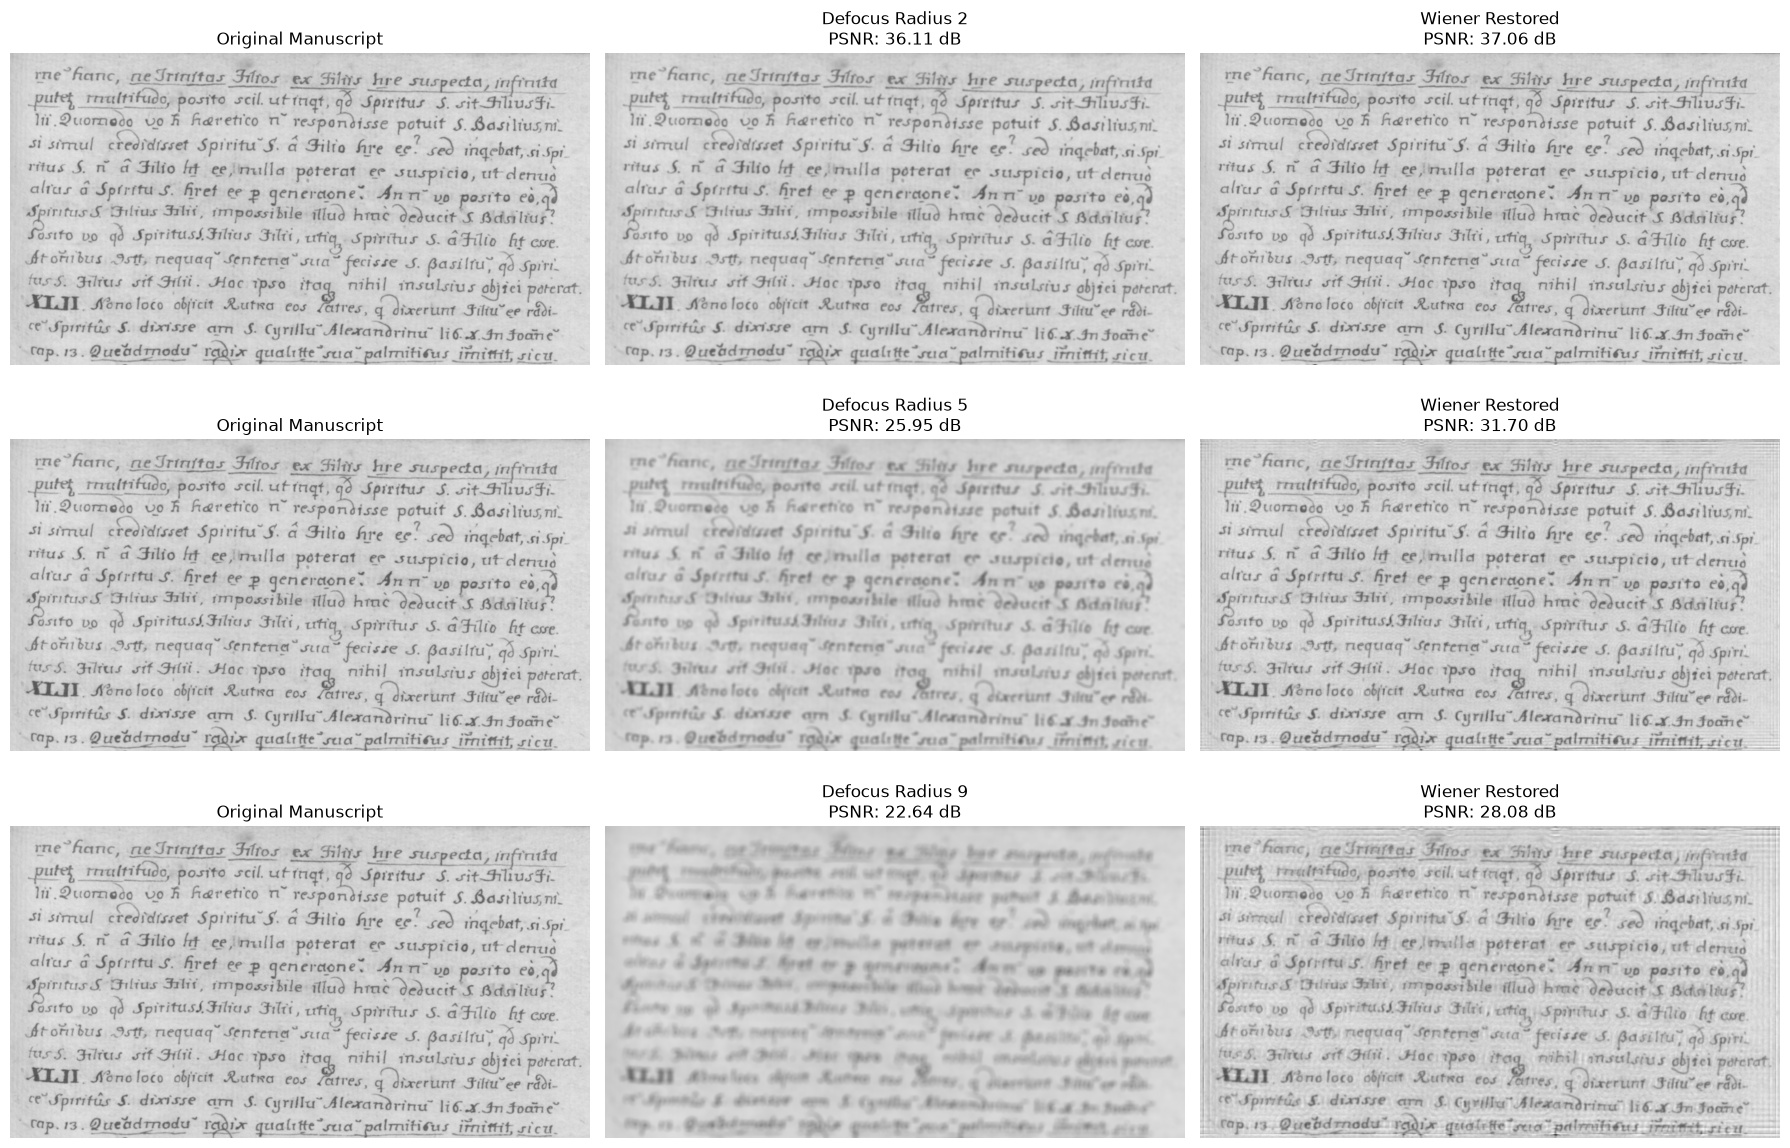

In [8]:
# Define the different defocus blur strengths
radii = [2, 5, 9]

# Create 3 rows (one per radius) and 3 columns
fig, axes = plt.subplots(3, 3, figsize=(18, 12))

# Loop through each radius
for i, radius in enumerate(radii):

    # Generate a circular blur kernel for this radius
    kernel = create_defocus_kernel(radius)

    # Apply defocus blur to the original manuscript
    blurred = cv2.filter2D(original, -1, kernel)

    # Restore the blurred image using Wiener deconvolution
    restored = wiener_deblur(
        blurred,
        kernel,
        K=0.001887
    )

    # Measure how much the blur changed the original
    blurred_score = psnr(original, blurred, data_range=255)

    # Measure how close the restoration is to the original
    restored_score = psnr(original, restored, data_range=255)

    # Print results for each radius
    print(
        f"Radius {radius} | "
        f"Blurred: {blurred_score:.2f} dB | "
        f"Restored: {restored_score:.2f} dB | "
        f"Improvement: {restored_score - blurred_score:.2f} dB"
    )

    # Store images and their titles
    images = [original, blurred, restored]

    titles = [
        "Original Manuscript",
        f"Defocus Radius {radius}\nPSNR: {blurred_score:.2f} dB",
        f"Wiener Restored\nPSNR: {restored_score:.2f} dB"
    ]

    # Display all three images for this radius
    for j in range(3):
        axes[i, j].imshow(
            images[j],
            cmap="gray",
            vmin=0,
            vmax=255
        )
        axes[i, j].set_title(titles[j])
        axes[i, j].axis("off")

# Adjust spacing between images
plt.tight_layout()
plt.show()

## Incorrect Kernel

In [9]:
# Actual kernel used to blur the image
actual_kernel = create_defocus_kernel(radius=9)

# Blur the original image
blurred = cv2.filter2D(
    original,
    -1,
    actual_kernel
)

# Incorrect kernel supplied to Wiener
wrong_kernel = create_defocus_kernel(radius=3)

# Attempt restoration using the WRONG kernel
restored_wrong = wiener_deblur(
    blurred,
    wrong_kernel,
    K=0.001887
)

# Restoration using the CORRECT kernel
restored_correct = wiener_deblur(
    blurred,
    actual_kernel,
    K=0.001887
)

Blurred Image: 22.64 dB
Wrong Kernel (Radius 3): 22.44 dB
Correct Kernel (Radius 9): 28.08 dB


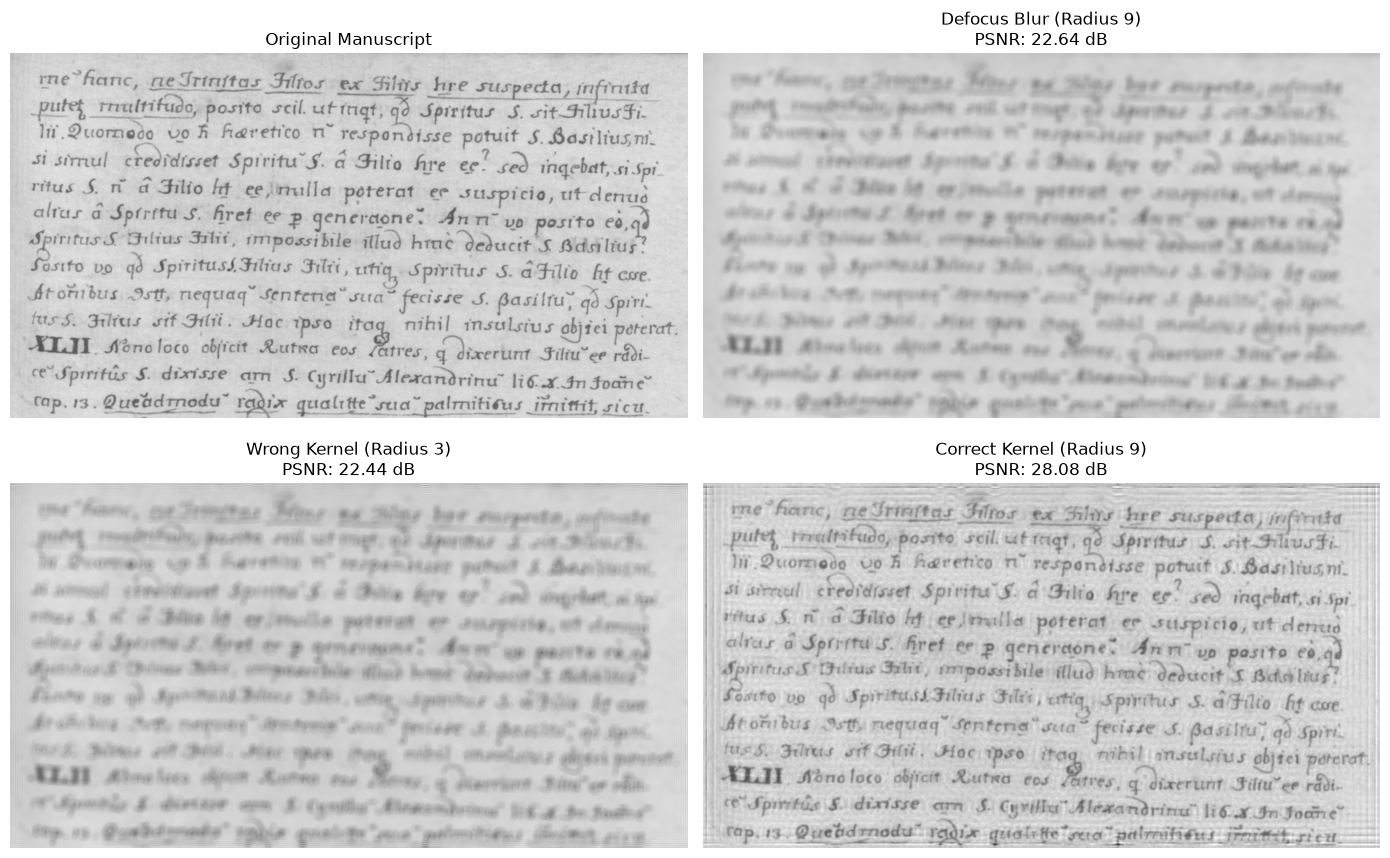

In [10]:
# Calculate PSNR for each image
blurred_psnr = psnr(original, blurred, data_range=255)

wrong_psnr = psnr(original, restored_wrong, data_range=255)

correct_psnr = psnr(original, restored_correct, data_range=255)

# Print the results
print(f"Blurred Image: {blurred_psnr:.2f} dB")
print(f"Wrong Kernel (Radius 3): {wrong_psnr:.2f} dB")
print(f"Correct Kernel (Radius 9): {correct_psnr:.2f} dB")

# Create a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Store images and titles
images = [
    original,
    blurred,
    restored_wrong,
    restored_correct
]

titles = [
    "Original Manuscript",
    f"Defocus Blur (Radius 9)\nPSNR: {blurred_psnr:.2f} dB",
    f"Wrong Kernel (Radius 3)\nPSNR: {wrong_psnr:.2f} dB",
    f"Correct Kernel (Radius 9)\nPSNR: {correct_psnr:.2f} dB"
]

# Display each image
for ax, image, title in zip(axes.flat, images, titles):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Automatic Defocus Kernel Estimation — Frequency Analysis

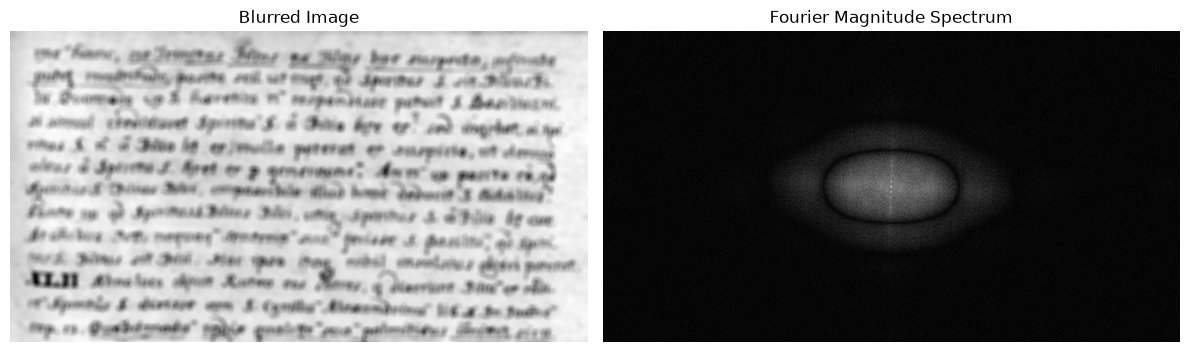

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Convert the blurred image to floating point
img = test_blurred.astype(np.float32) / 255.0

# Apply a window to reduce boundary artifacts
window_y = np.hanning(img.shape[0])
window_x = np.hanning(img.shape[1])
window = np.outer(window_y, window_x)

# Compute the Fourier transform
fft = np.fft.fftshift(np.fft.fft2(img * window))

# Calculate the log magnitude spectrum
spectrum = np.log1p(np.abs(fft))

# Display image and frequency spectrum
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(blurred, cmap="gray")
axes[0].set_title("Blurred Image")

axes[1].imshow(spectrum, cmap="gray")
axes[1].set_title("Fourier Magnitude Spectrum")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

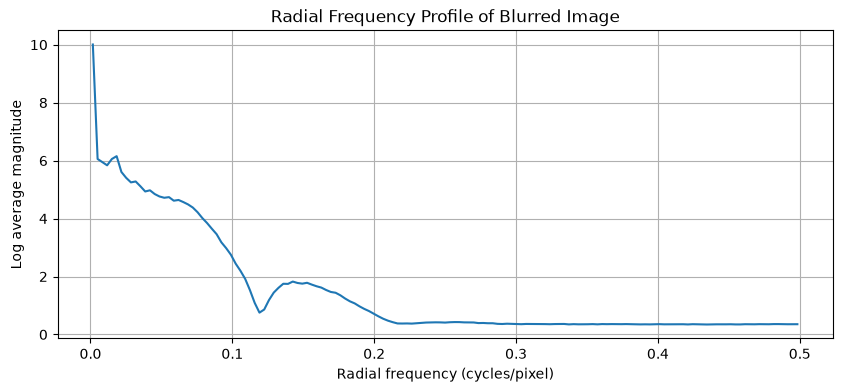

In [20]:
# Frequency coordinates (cycles per pixel)
fy = np.fft.fftshift(np.fft.fftfreq(img.shape[0]))
fx = np.fft.fftshift(np.fft.fftfreq(img.shape[1]))

FX, FY = np.meshgrid(fx, fy)

# Radial frequency at every pixel
radius = np.sqrt(FX**2 + FY**2)

# Group frequencies into radial bins
bins = np.linspace(0, 0.5, 150)

radial_profile = []
centres = []

for i in range(len(bins) - 1):
    mask = (radius >= bins[i]) & (radius < bins[i + 1])

    if np.any(mask):
        radial_profile.append(np.mean(np.abs(fft)[mask]))
        centres.append((bins[i] + bins[i + 1]) / 2)

# Plot radial frequency profile
plt.figure(figsize=(10, 4))
plt.plot(centres, np.log1p(radial_profile))

plt.xlabel("Radial frequency (cycles/pixel)")
plt.ylabel("Log average magnitude")
plt.title("Radial Frequency Profile of Blurred Image")
plt.grid(True)
plt.show()

In [21]:
from scipy.signal import find_peaks

def estimate_defocus_radius(centres, radial_profile):
    # Convert the frequency data into NumPy arrays
    frequencies = np.array(centres)
    profile = np.log1p(np.array(radial_profile))

    # Find dips in the frequency spectrum
    minima, _ = find_peaks(-profile, prominence=0.3)

    # Only consider frequencies in our search range
    valid = minima[
    (frequencies[minima] > 0.03) &
    (frequencies[minima] < 0.45)
]

    if len(valid) == 0:
        return None

    # Take the first significant minimum
    first_frequency = frequencies[valid[0]]

    # Estimate radius from the first zero of a disk kernel
    estimated_radius = 0.61 / first_frequency

    return estimated_radius

In [16]:
radius = estimate_defocus_radius(centres, radial_profile)

print(f"Estimated radius: {radius:.2f}" if radius is not None
      else "Could not estimate radius")

Estimated radius: 8.87


In [18]:
# Generate an image with defocus radius 5
test_kernel = create_defocus_kernel(radius=5)
test_blurred = cv2.filter2D(original, -1, test_kernel)

# Estimate the radius using the same Fourier process
img = test_blurred.astype(np.float32) / 255.0

Blurred PSNR: 25.95 dB
Restored PSNR: 28.08 dB
Improvement: 2.13 dB


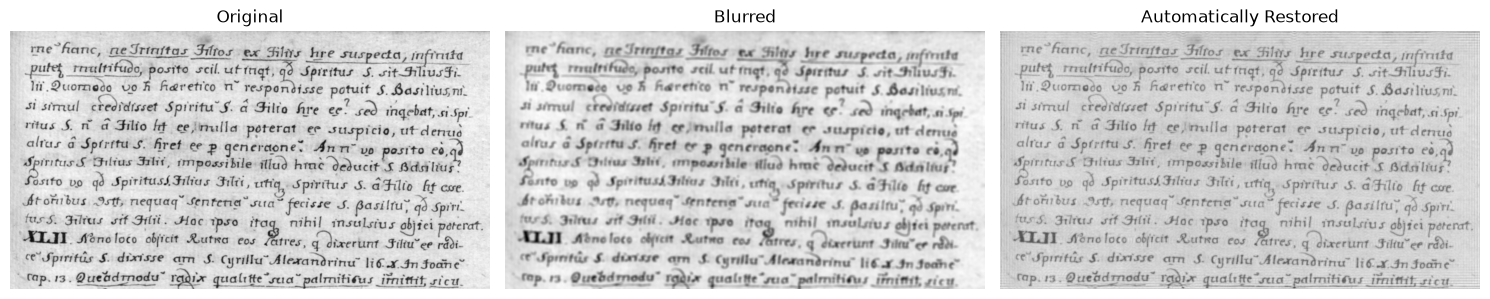

Estimated radius: 5


In [22]:
# Estimate the defocus radius from the blurred image
estimated_radius = estimate_defocus_radius(centres, radial_profile)

if estimated_radius is not None:
    blurred_psnr = cv2.PSNR(original, test_blurred)
    restored_psnr = cv2.PSNR(original, restored)

    print(f"Blurred PSNR: {blurred_psnr:.2f} dB")
    print(f"Restored PSNR: {restored_psnr:.2f} dB")
    print(f"Improvement: {restored_psnr - blurred_psnr:.2f} dB")

    # Convert the estimated radius to an integer
    estimated_radius = round(estimated_radius)

    # Generate the estimated defocus kernel
    estimated_kernel = create_defocus_kernel(estimated_radius)

    # Restore the image using Wiener deconvolution
    restored = wiener_deblur(
        test_blurred,
        estimated_kernel,
        K=0.001887
    )

    # Display the results
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for ax, image, title in zip(
        axes,
        [original, test_blurred, restored],
        ["Original", "Blurred", "Automatically Restored"]
    ):
        ax.imshow(image, cmap="gray")
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"Estimated radius: {estimated_radius}")

else:
    print("Could not estimate kernel. Restoration skipped.")